# TSP restringido mediante QUBO y Simulated Annealing

Problema de optimización inspirado en el viajante de comercio (TSP).

Objetivo: ruta de coste mínimo que:

- parte de la ciudad 0 y termina en la ciudad 0,
- visita una sola vez cada ciudad,
- impone que la ciudad **2** sea la **segunda ciudad visitada** tras salir del origen:
  $0 \rightarrow x \rightarrow 2 \rightarrow \cdots \rightarrow 0$.

El problema se modela como QUBO (formato compatible con annealing tipo D-Wave).
Sin acceso a solvers de D-Wave, se resuelve con **Simulated Annealing**, técnica clásica
relacionada conceptualmente con Quantum Annealing.


## Librerías


In [25]:
import itertools
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


## 1. Definición del grafo

Cinco ciudades: $V = \{0,1,2,3,4\}$. La ciudad $0$ es el origen.

Distancias del enunciado:

$d_{01}=3,\quad d_{03}=4,\quad d_{04}=2$

$d_{12}=3,\quad d_{13}=4$

$d_{23}=1,\quad d_{24}=6$

La distancia $0$–$2$ no viene en el enunciado; se asigna $d_{02}=4$
(misma escala, sin favorecer en exceso esa arista).


In [26]:
nodes = [0, 1, 2, 3, 4]
origin = 0

# Distancia elegida para la arista no especificada en el enunciado
d02 = 4

dist = {
    (0, 1): 3,
    (0, 2): d02,
    (0, 3): 4,
    (0, 4): 2,
    (1, 2): 3,
    (1, 3): 4,
    (2, 3): 1,
    (2, 4): 6,
}

# Grafo no dirigido: distancias simétricas
for (i, j), value in list(dist.items()):
    dist[(j, i)] = value

# Penalización para aristas inexistentes
BIG_M = 100


def edge_exists(i, j):
    return (i, j) in dist


def cost(i, j):
    """Coste de viajar de i a j; arista inexistente → penalización grande."""
    if i == j:
        return BIG_M
    return dist.get((i, j), BIG_M)


## 2. Visualización del grafo

Las aristas inexistentes no se dibujan. En el modelo se penalizan con $M$.


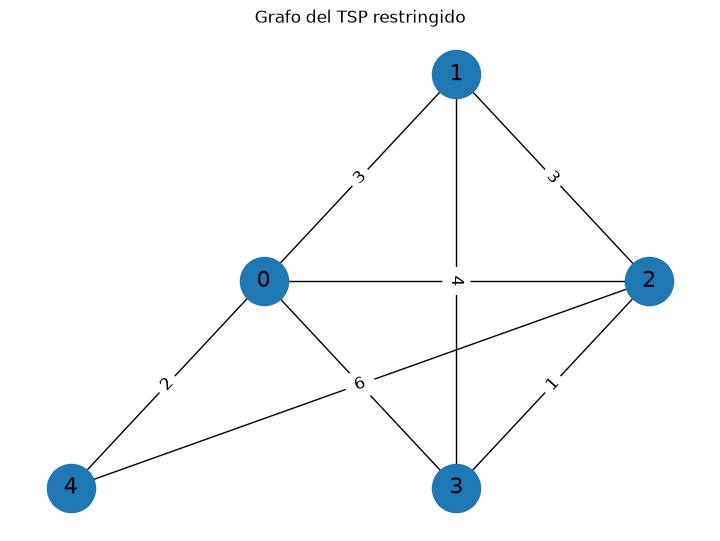

In [27]:
G = nx.Graph()
for node in nodes:
    G.add_node(node)

for (i, j), w in dist.items():
    if i < j:
        G.add_edge(i, j, weight=w)

pos = {
    0: (0, 0),
    1: (1, 1),
    2: (2, 0),
    3: (1, -1),
    4: (-1, -1),
}

plt.figure(figsize=(7, 5))
nx.draw(G, pos, with_labels=True, node_size=1200, font_size=16)
labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=12)
plt.title("Grafo del TSP restringido")
plt.show()


## 3. Restricción sobre la ciudad 2

La ciudad $2$ debe ser la **segunda ciudad visitada** después de salir del origen:

$0 \rightarrow x \rightarrow 2 \rightarrow \cdots \rightarrow 0$

Es decir, en la secuencia de la ruta, la ciudad $2$ aparece en la posición de índice $2$
(`route[2] == 2`).


In [28]:
def route_cost(route):
    """Coste total de una ruta."""
    return sum(cost(route[i], route[i + 1]) for i in range(len(route) - 1))


def is_valid_route(route):
    """Comprueba inicio/fin en origen, visita única y restricción de la ciudad 2."""
    if route[0] != origin or route[-1] != origin:
        return False
    if sorted(route[1:-1]) != [1, 2, 3, 4]:
        return False
    # Segunda ciudad visitada tras el origen = 2
    return route[2] == 2


## 4. Generación de rutas candidatas

Con cuatro ciudades distintas del origen hay $4! = 24$ permutaciones antes de la restricción.
Se conservan solo las que cumplen `route[2] == 2` y se calcula su coste.

Aristas inexistentes → penalización $M=100$.


In [29]:
def generate_candidate_routes():
    """Genera todas las rutas candidatas que cumplen las restricciones."""
    candidates = []
    for perm in itertools.permutations([1, 2, 3, 4]):
        route = [origin] + list(perm) + [origin]
        if is_valid_route(route):
            candidates.append({
                "route": route,
                "cost": route_cost(route),
                "uses_invalid_edges": any(
                    not edge_exists(route[i], route[i + 1])
                    for i in range(len(route) - 1)
                ),
            })
    return candidates


candidates = generate_candidate_routes()
print(f"Rutas candidatas: {len(candidates)}")
for candidate in candidates:
    print(
        candidate["route"],
        "coste =", candidate["cost"],
        "usa aristas inexistentes =", candidate["uses_invalid_edges"],
    )


Rutas candidatas: 6
[0, 1, 2, 3, 4, 0] coste = 109 usa aristas inexistentes = True
[0, 1, 2, 4, 3, 0] coste = 116 usa aristas inexistentes = True
[0, 3, 2, 1, 4, 0] coste = 110 usa aristas inexistentes = True
[0, 3, 2, 4, 1, 0] coste = 114 usa aristas inexistentes = True
[0, 4, 2, 1, 3, 0] coste = 19 usa aristas inexistentes = False
[0, 4, 2, 3, 1, 0] coste = 16 usa aristas inexistentes = False


## 5. Solución óptima de referencia

Antes del QUBO, se calcula la mejor ruta por enumeración (referencia para validar el annealing).

Se distingue entre:

- rutas solo con aristas existentes,
- rutas que usan alguna arista inexistente (penalización $M$).


In [30]:
def best_candidate(candidates, allow_invalid_edges=True):
    pool = candidates
    if not allow_invalid_edges:
        pool = [c for c in candidates if not c["uses_invalid_edges"]]
    if not pool:
        return None
    return min(pool, key=lambda c: c["cost"])


best_with_penalty = best_candidate(candidates, allow_invalid_edges=True)
best_strict = best_candidate(candidates, allow_invalid_edges=False)

print("Mejor ruta permitiendo penalizaciones:")
print(best_with_penalty)
print("\nMejor ruta usando solo aristas existentes:")
print(best_strict)


Mejor ruta permitiendo penalizaciones:
{'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}

Mejor ruta usando solo aristas existentes:
{'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}


## 6. Formulación QUBO reducida

Modelo QUBO reducido: una variable binaria por ruta candidata

$y_k =
\begin{cases}
1, & \text{si se selecciona la ruta } k \\
0, & \text{en caso contrario}
\end{cases}$

Energía:

$E(y)=\sum_k c_k y_k + A\left(1-\sum_k y_k\right)^2$

- $c_k$: coste de la ruta $k$,
- $A$: penalización por seleccionar cero o más de una ruta.

Es QUBO porque la función es cuadrática en variables binarias.


In [31]:
def qubo_energy(state, candidates, penalty=100):
    """Energía QUBO: state[k]=1 selecciona la ruta candidata k."""
    costs = np.array([candidate["cost"] for candidate in candidates])
    y = np.array(state)
    route_cost_term = np.dot(costs, y)
    constraint_penalty = penalty * (1 - np.sum(y)) ** 2
    return route_cost_term + constraint_penalty


## 7. Ejemplo de energía QUBO

Si se selecciona exactamente una ruta, la penalización es cero y la energía coincide con su coste.
Si se seleccionan cero o varias rutas, aparece la penalización $A$.


In [32]:
print("Rutas candidatas:")
for k, candidate in enumerate(candidates):
    print(k, candidate)

print("\nEjemplo seleccionando la primera ruta:")
state = [1] + [0] * (len(candidates) - 1)
print("Estado:", state)
print("Energía:", qubo_energy(state, candidates, penalty=100))

print("\nEjemplo seleccionando ninguna ruta:")
state = [0] * len(candidates)
print("Estado:", state)
print("Energía:", qubo_energy(state, candidates, penalty=100))

print("\nEjemplo seleccionando dos rutas:")
state = [1, 1] + [0] * (len(candidates) - 2)
print("Estado:", state)
print("Energía:", qubo_energy(state, candidates, penalty=100))


Rutas candidatas:
0 {'route': [0, 1, 2, 3, 4, 0], 'cost': 109, 'uses_invalid_edges': True}
1 {'route': [0, 1, 2, 4, 3, 0], 'cost': 116, 'uses_invalid_edges': True}
2 {'route': [0, 3, 2, 1, 4, 0], 'cost': 110, 'uses_invalid_edges': True}
3 {'route': [0, 3, 2, 4, 1, 0], 'cost': 114, 'uses_invalid_edges': True}
4 {'route': [0, 4, 2, 1, 3, 0], 'cost': 19, 'uses_invalid_edges': False}
5 {'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}

Ejemplo seleccionando la primera ruta:
Estado: [1, 0, 0, 0, 0, 0]
Energía: 109

Ejemplo seleccionando ninguna ruta:
Estado: [0, 0, 0, 0, 0, 0]
Energía: 100

Ejemplo seleccionando dos rutas:
Estado: [1, 1, 0, 0, 0, 0]
Energía: 325


## 8. Resolución mediante Simulated Annealing

Simulated Annealing parte de un estado inicial y propone cambios aleatorios.
Si el cambio mejora la energía, se acepta; si empeora, puede aceptarse con

$P = e^{-\Delta E/T}$

Al inicio $T$ es alta (más exploración); al enfriar, el algoritmo se vuelve más selectivo.


In [33]:
def random_state(n):
    """Estado binario aleatorio de longitud n."""
    return [random.randint(0, 1) for _ in range(n)]


def neighbor_state(state):
    """Vecino: flip de un bit aleatorio."""
    new_state = state.copy()
    index = random.randint(0, len(state) - 1)
    new_state[index] = 1 - new_state[index]
    return new_state


def simulated_annealing(
    candidates,
    penalty=100,
    max_iter=5000,
    initial_temperature=50,
    cooling_rate=0.995,
    seed=42,
):
    """Resuelve el QUBO reducido mediante Simulated Annealing."""
    random.seed(seed)

    n = len(candidates)
    current_state = random_state(n)
    current_energy = qubo_energy(current_state, candidates, penalty)
    energy_evals = 1

    best_state = current_state.copy()
    best_energy = current_energy
    best_iter = 0
    temperature = initial_temperature
    history = []

    for it in range(max_iter):
        candidate_state = neighbor_state(current_state)
        candidate_energy = qubo_energy(candidate_state, candidates, penalty)
        energy_evals += 1
        delta = candidate_energy - current_energy

        if delta < 0:
            accept = True
        else:
            accept_probability = math.exp(-delta / temperature) if temperature > 0 else 0
            accept = random.random() < accept_probability

        if accept:
            current_state = candidate_state
            current_energy = candidate_energy

        if current_energy < best_energy:
            best_state = current_state.copy()
            best_energy = current_energy
            best_iter = it + 1

        history.append(current_energy)
        temperature *= cooling_rate

    return {
        "best_state": best_state,
        "best_energy": float(best_energy),
        "history": history,
        "energy_evals": int(energy_evals),
        "best_iter": int(best_iter),
        "max_iter": int(max_iter),
    }


## 9. Ejecución del algoritmo

Se ejecuta Simulated Annealing (run de referencia, `seed=42`) y se decodifica la ruta.
Después se repite en varias semillas para métricas de eficiencia / éxito.


In [34]:
def decode_selected_route(state, candidates):
    """Convierte un estado binario en la ruta seleccionada."""
    selected_indices = [i for i, bit in enumerate(state) if bit == 1]
    if len(selected_indices) != 1:
        return None
    return candidates[selected_indices[0]]


SA_PARAMS = dict(
    penalty=100,
    max_iter=5000,
    initial_temperature=50,
    cooling_rate=0.995,
)

t0 = time.perf_counter()
sa_ref = simulated_annealing(candidates, seed=42, **SA_PARAMS)
ref_time = time.perf_counter() - t0

best_state = sa_ref["best_state"]
best_energy = sa_ref["best_energy"]
history = sa_ref["history"]
selected_route = decode_selected_route(best_state, candidates)

print("Mejor estado binario:", best_state)
print("Mejor energía:", best_energy)
print("Ruta seleccionada:", selected_route)
print("Óptimo por enumeración:", best_strict)
print(f"Tiempo run referencia: {ref_time:.4f}s | evals energía: {sa_ref['energy_evals']}")


Mejor estado binario: [0, 0, 0, 0, 0, 1]
Mejor energía: 16.0
Ruta seleccionada: {'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}
Óptimo por enumeración: {'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}
Tiempo run referencia: 0.1086s | evals energía: 5001


## 10. Análisis de resultados

Simulated Annealing obtiene la ruta

$[0, 4, 2, 3, 1, 0]$

con coste $16$. Usa solo aristas existentes y coincide con el óptimo por enumeración.


## 11. Convergencia del algoritmo

La energía baja hasta el mínimo global y se estabiliza: comportamiento típico de Simulated Annealing
y coherente con el QUBO reducido.


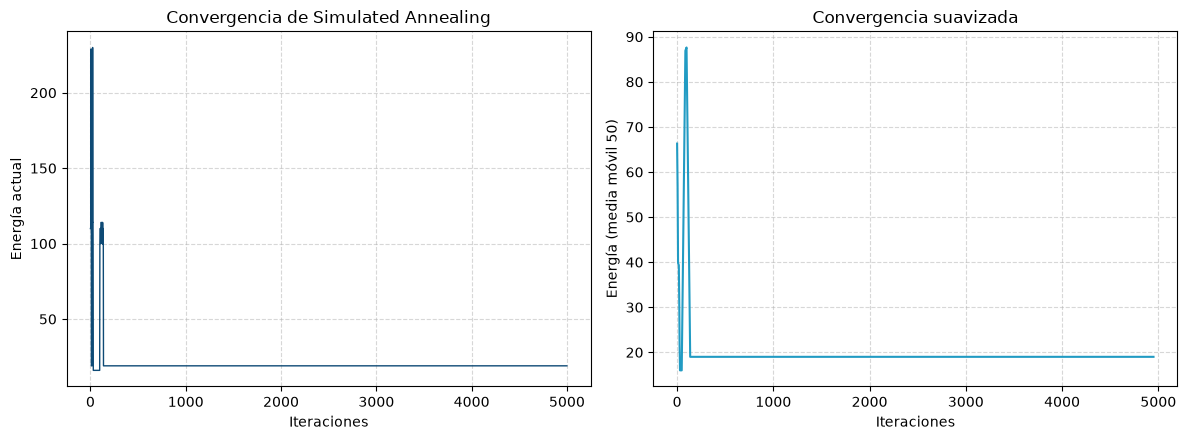

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

axs[0].plot(history, color="#0E4A75", lw=1)
axs[0].set_xlabel("Iteraciones")
axs[0].set_ylabel("Energía actual")
axs[0].set_title("Convergencia de Simulated Annealing")
axs[0].grid(True, linestyle="--", alpha=0.5)

window = 50
smoothed = np.convolve(history, np.ones(window) / window, mode="valid")
axs[1].plot(smoothed, color="#219BC3", lw=1.5)
axs[1].set_xlabel("Iteraciones")
axs[1].set_ylabel(f"Energía (media móvil {window})")
axs[1].set_title("Convergencia suavizada")
axs[1].grid(True, linestyle="--", alpha=0.5)

fig.tight_layout()
plt.show()


## 12. Métricas de eficiencia (para comparación clásica)

Protocolo reproducible: $N$ semillas independientes con los mismos hiperparámetros.
Se registran calidad (coste, gap, factibilidad), éxito y esfuerzo (tiempo, evaluaciones de energía).

Salida: `Notebooks/Optimization/TSPOptimization/metrics/sa_tsp.json`


In [36]:
N_RUNS = 20
SEEDS = list(range(N_RUNS))
OPTIMAL_COST = float(best_strict["cost"]) if best_strict is not None else None

run_rows = []
for seed in SEEDS:
    t0 = time.perf_counter()
    out = simulated_annealing(candidates, seed=seed, **SA_PARAMS)
    elapsed = time.perf_counter() - t0
    selected = decode_selected_route(out["best_state"], candidates)
    feasible = selected is not None and (not selected["uses_invalid_edges"])
    cost = float(selected["cost"]) if selected is not None else float("nan")
    gap = None if (OPTIMAL_COST is None or selected is None) else float(cost - OPTIMAL_COST)
    success = bool(
        selected is not None
        and OPTIMAL_COST is not None
        and abs(cost - OPTIMAL_COST) < 1e-9
        and feasible
    )
    run_rows.append({
        "seed": int(seed),
        "cost": None if selected is None else cost,
        "energy": out["best_energy"],
        "feasible": feasible,
        "success": success,
        "gap": gap,
        "time_s": float(elapsed),
        "energy_evals": out["energy_evals"],
        "best_iter": out["best_iter"],
        "route": None if selected is None else selected["route"],
    })

costs = np.array([r["cost"] for r in run_rows if r["cost"] is not None], dtype=float)
times = np.array([r["time_s"] for r in run_rows], dtype=float)
evals = np.array([r["energy_evals"] for r in run_rows], dtype=float)
success_rate = float(np.mean([r["success"] for r in run_rows]))

payload = {
    "problem": "tsp",
    "solver": "simulated_annealing",
    "family": "classical",
    "protocol": {
        "n_runs": N_RUNS,
        "seeds": SEEDS,
        "penalty": SA_PARAMS["penalty"],
        "max_iter": SA_PARAMS["max_iter"],
        "initial_temperature": SA_PARAMS["initial_temperature"],
        "cooling_rate": SA_PARAMS["cooling_rate"],
        "n_candidates": len(candidates),
        "n_qubo_vars": len(candidates),
        "constraint": "route[2]==2 (city 2 is second visited after origin)",
    },
    "instance": {
        "nodes": nodes,
        "origin": origin,
        "d02": d02,
        "big_m": BIG_M,
    },
    "quality": {
        "optimal_cost": OPTIMAL_COST,
        "optimal_route": None if best_strict is None else best_strict["route"],
        "cost_mean": float(np.nanmean(costs)) if len(costs) else None,
        "cost_std": float(np.nanstd(costs)) if len(costs) else None,
        "cost_best": float(np.nanmin(costs)) if len(costs) else None,
        "gap_mean": None if OPTIMAL_COST is None or not len(costs) else float(np.nanmean(costs - OPTIMAL_COST)),
    },
    "success_rate": success_rate,
    "time_s": {
        "mean": float(np.mean(times)),
        "std": float(np.std(times)),
        "total": float(np.sum(times)),
    },
    "effort": {
        "energy_evals_mean": float(np.mean(evals)),
        "energy_evals_per_run": SA_PARAMS["max_iter"] + 1,
        "p": None,
        "shots": None,
    },
    "reference_run": {
        "seed": 42,
        "time_s": float(ref_time),
        "energy": float(best_energy),
        "route": None if selected_route is None else selected_route["route"],
        "cost": None if selected_route is None else float(selected_route["cost"]),
    },
    "runs": run_rows,
}


def resolve_tsp_metrics_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        metrics_dir = base / "Notebooks" / "Optimization" / "TSPOptimization" / "metrics"
        if (base / "Notebooks" / "Optimization" / "TSPOptimization").is_dir():
            metrics_dir.mkdir(parents=True, exist_ok=True)
            return metrics_dir
    metrics_dir = Path.cwd().resolve() / "Notebooks" / "Optimization" / "TSPOptimization" / "metrics"
    metrics_dir.mkdir(parents=True, exist_ok=True)
    return metrics_dir


metrics_dir = resolve_tsp_metrics_dir()
out_path = metrics_dir / "sa_tsp.json"
out_path.write_text(json.dumps(payload, indent=2))
print(f"success_rate={success_rate:.3f} | cost_mean={payload['quality']['cost_mean']} | time_mean={payload['time_s']['mean']:.4f}s")
print("Saved:", out_path)


success_rate=0.900 | cost_mean=16.3 | time_mean=0.0172s
Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/metrics/sa_tsp.json


## Storytelling plots

Figuras para documento/slides → `figures/`.


In [ ]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

from storytelling import (
    resolve_figures_dir,
    plot_tsp_instance, plot_tsp_route,
)

figures_dir = resolve_figures_dir("Optimization", "TSPOptimization")
plot_tsp_instance(nodes, dist, figures_dir, stem="instance")
# ruta del solver: payload runs o sol
_route = None
if "payload" in globals() and payload.get("runs"):
    _runs = [r for r in payload["runs"] if r.get("route") is not None]
    if _runs:
        _route = min(_runs, key=lambda r: float(r.get("cost", 1e18))).get("route")
if _route is None and "sol" in globals():
    _route = sol["route"] if isinstance(sol, dict) else sol
if _route is None and "OPTIMAL" in globals():
    _route = OPTIMAL.get("route")
if _route is None:
    raise RuntimeError("No TSP route found for storytelling plot")
plot_tsp_route(nodes, dist, _route, figures_dir, stem="sa", title="Simulated Annealing")
